In [2]:
# Building an pre-processing pipeline from scratch 

# We need to install some liberaries before startoing:--
import os 
import cv2
import numpy as np
import json
import matplotlib.pyplot as plt
import random
from collections import Counter, defaultdict


In [3]:
folder_image_path = "D:\\Camera_trap\\data\\raw_data\\eccv_18_all_images_sm"

image_base_path = "D:\\Camera_trap\\data\\raw_data\\eccv_18_annotation_files\\caltech_bboxes_20200316.json"

# Loading bbox annotation:-
with open (image_base_path) as f:
    data_bbox = json.load(f)

# Fetching list of downloaded images:--
images_downloaded = set(os.listdir(folder_image_path))

# Fast lookup: image_id -> (width, height) AS STATED IN THE ANNOTATION FILE.
# IMPORTANT: the downloaded 'eccv_18_all_images_sm' files are downscaled
# copies of the originals — their actual pixel size does NOT match this.
# The bbox coordinates in the JSON are defined relative to THESE
# (original) dimensions, not the actual downloaded file size. This is
# why scaling must always use image_dimensions below, never img.shape
# read directly from the downloaded file.
image_dimensions = {img["id"]: (img["width"], img["height"]) for img in data_bbox["images"]}

print(f"Annotations: {len(data_bbox['annotations'])}")
print(f"Images {len(images_downloaded)}")


Annotations: 65112
Images 57864


In [4]:
# Hene we have got 57864 images with 65112 annotation:--
# Note: not every annotation has a matching downloaded image file.
# This is expected and is handled later with an os.path.exists() check
# in the main preprocessing loop, so no images/annotations are lost silently.


In [5]:
# Resizing images :--
# We have images of two different sizes :--
# requirnment :-- 640 * 640
# bbox coordinates needs to resize:--

required_size = (640,640)
print(f" Ideal size {required_size}")


 Ideal size (640, 640)


In [6]:
# Resizing function :--
# CORRECTED: scale factors must be computed from the ORIGINAL image
# dimensions stated in the annotation JSON (image_dimensions), not from
# the actual downloaded file's dimensions. The downloaded 'eccv_18_all_
# images_sm' files are downscaled copies — their real pixel size does
# not match what the bbox coordinates were defined against. Using the
# wrong dimensions here caused bounding boxes to render in the wrong
# position/size when drawn for visualisation.
def image_resizing (image_base_path, image_id):
    img = cv2.imread (image_base_path)  # Loading of image

    # Use ORIGINAL dimensions from the annotation file, not img.shape
    width_image, length_image = image_dimensions[image_id]

    change_size_image = cv2.resize (img,required_size)  # We need an ideal image size of 640, 640

    # Getting the value need to be multiplied while resizing boundinf box:--
    x_scale = required_size[0] / width_image
    y_scale = required_size[1] / length_image

    return change_size_image, x_scale, y_scale


In [7]:
# Resizing of image is done now we need to write resizing for bounbding boxes as well using x_scale and y_scale:--
def bbox_resizing(bbox,x_scale,y_scale):
    x,y,w,h = bbox
    update_x = x * x_scale
    update_y = y * y_scale
    update_w = w * x_scale
    update_h = h * y_scale
    return [update_x,update_y,update_w,update_h]


In [8]:
# ============================================================
# Helper: pick the best annotation for a given image_id
# ============================================================
# Some images have more than one annotation. This picks the LARGEST
# valid (non-edge-clipped) box, checked against the ORIGINAL image
# dimensions from the annotation file (see note in Cell 1 / Cell 4).

def get_best_annotation(image_id, margin=2):
    matches = [a for a in data_bbox["annotations"] if a["image_id"] == image_id]

    if not matches:
        return None

    if image_id not in image_dimensions:
        return matches[0]  # fall back if dimensions unknown

    img_w, img_h = image_dimensions[image_id]

    valid = []
    for ann in matches:
        x, y, w, h = ann["bbox"]
        if x < margin or y < margin:
            continue
        if (x + w) > (img_w - margin) or (y + h) > (img_h - margin):
            continue
        valid.append(ann)

    pool = valid if valid else matches
    pool.sort(key=lambda a: a["bbox"][2] * a["bbox"][3], reverse=True)
    return pool[0]

print("Helper ready")


Helper ready


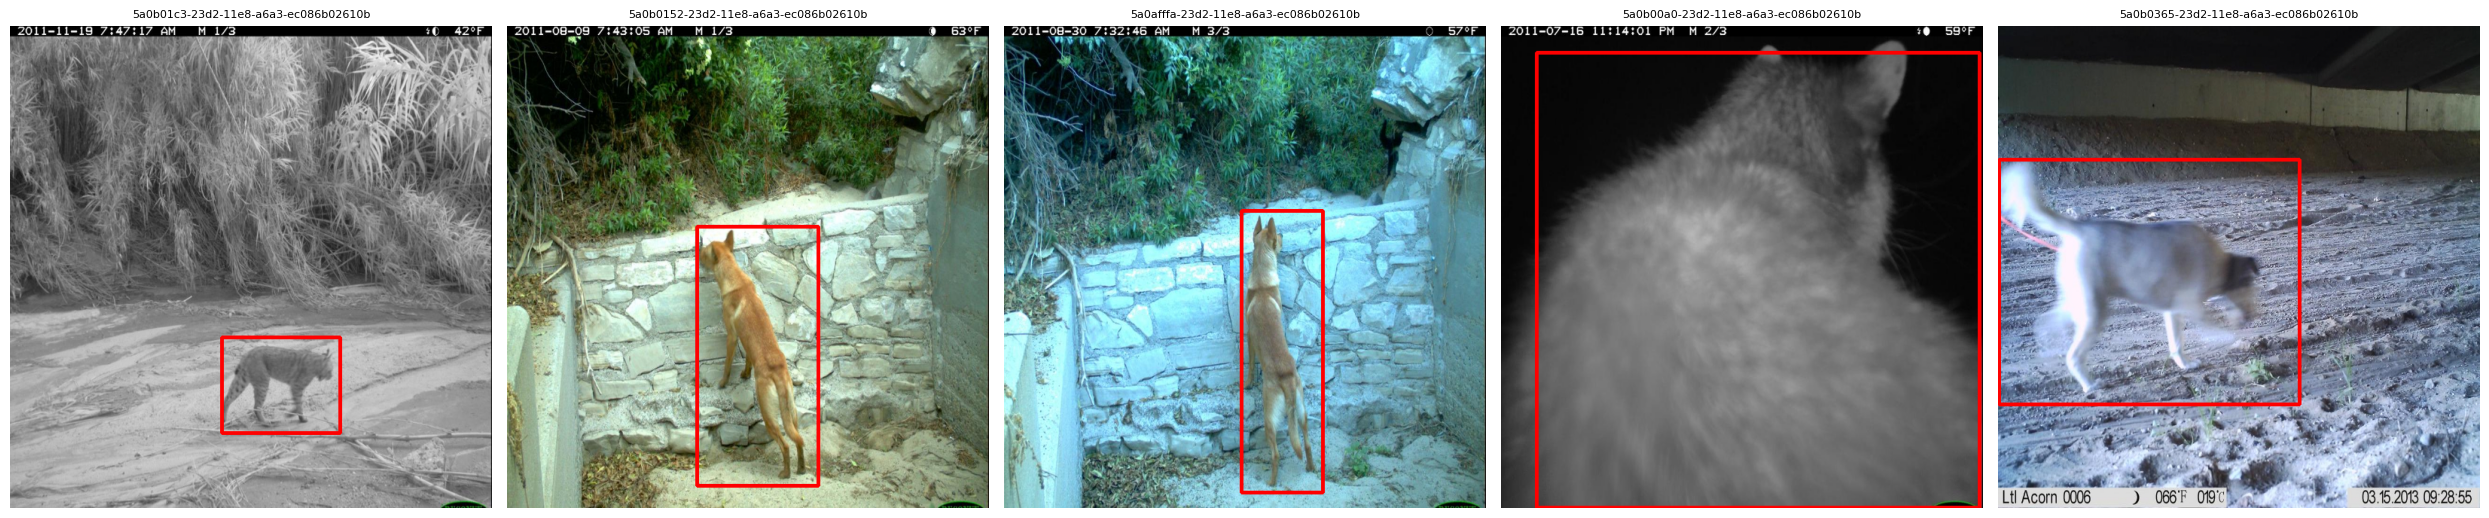

In [9]:
# ============================================================
# Example gallery — 5 real images with their bounding boxes
# ============================================================
example_image_ids = [
    "5a0b01c3-23d2-11e8-a6a3-ec086b02610b",
    "5a0b0152-23d2-11e8-a6a3-ec086b02610b",
    "5a0afffa-23d2-11e8-a6a3-ec086b02610b",
    "5a0b00a0-23d2-11e8-a6a3-ec086b02610b",
    "5a0b0365-23d2-11e8-a6a3-ec086b02610b",
]

fig, axes = plt.subplots(1, 5, figsize=(25, 6))

for ax, img_id in zip(axes, example_image_ids):
    img_path = os.path.join(folder_image_path, img_id + ".jpg")

    if not os.path.exists(img_path):
        ax.set_title(f"{img_id}\n(file not found)", fontsize=9)
        ax.axis("off")
        continue

    ann = get_best_annotation(img_id)
    if ann is None:
        ax.set_title(f"{img_id}\n(no annotation)", fontsize=9)
        ax.axis("off")
        continue

    resized_img, sx, sy = image_resizing(img_path, img_id)
    resized_img_rgb = cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB)
    rx, ry, rw, rh = bbox_resizing(ann["bbox"], sx, sy)

    cv2.rectangle(resized_img_rgb, (int(rx), int(ry)), (int(rx + rw), int(ry + rh)), (255, 0, 0), 3)

    ax.imshow(resized_img_rgb)
    ax.set_title(img_id, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.savefig(r"D:\Camera_trap\reports\bbox_examples_5.png", dpi=200, bbox_inches="tight")
plt.show()


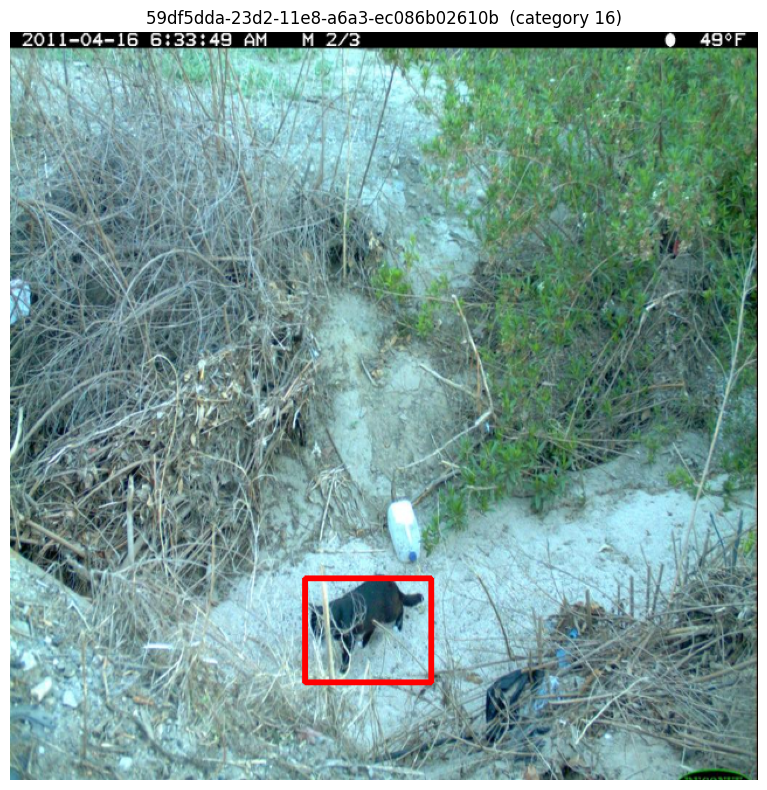

In [10]:
def show_image_with_bbox(image_id, save_path=None):
    """
    Display a specific image (by ID) with its bounding box drawn on it.
    Uses the corrected scaling (original dimensions from the annotation file).
    """
    img_path = os.path.join(folder_image_path, image_id + ".jpg")

    if not os.path.exists(img_path):
        print(f"Image file not found: {img_path}")
        return

    ann = get_best_annotation(image_id)
    if ann is None:
        print(f"No annotation found for image_id: {image_id}")
        return

    resized_img, sx, sy = image_resizing(img_path, image_id)
    resized_img_rgb = cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB)
    rx, ry, rw, rh = bbox_resizing(ann["bbox"], sx, sy)

    cv2.rectangle(
        resized_img_rgb,
        (int(rx), int(ry)),
        (int(rx + rw), int(ry + rh)),
        (255, 0, 0),
        3
    )

    plt.figure(figsize=(8, 8))
    plt.imshow(resized_img_rgb)
    plt.axis("off")
    plt.title(f"{image_id}  (category {ann['category_id']})")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()


# Example usage:
show_image_with_bbox("59df5dda-23d2-11e8-a6a3-ec086b02610b")

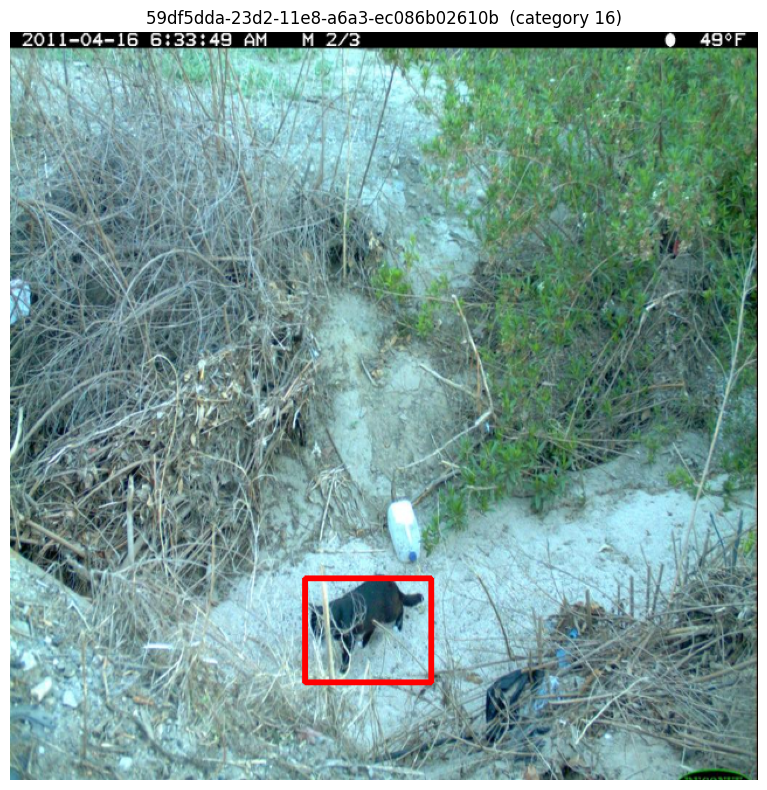

Image file not found: D:\Camera_trap\data\raw_data\eccv_18_all_images_sm\any-image-id-here.jpg


In [11]:
show_image_with_bbox("59df5dda-23d2-11e8-a6a3-ec086b02610b")

# or, to also save it as a file for your report/slides:
show_image_with_bbox("any-image-id-here", save_path=r"D:\Camera_trap\reports\my_example.png")

In [12]:
# Test the full combined pipeline on the first example image :--
test_image_id = example_image_ids[0]
test_image_annotation = get_best_annotation(test_image_id)
test_image_path = os.path.join(folder_image_path, test_image_id + ".jpg")

print("Path:", test_image_path)
print("Exists:", os.path.exists(test_image_path))
print("Annotation used:", test_image_annotation)


Path: D:\Camera_trap\data\raw_data\eccv_18_all_images_sm\5a0b01c3-23d2-11e8-a6a3-ec086b02610b.jpg
Exists: True
Annotation used: {'image_id': '5a0b01c3-23d2-11e8-a6a3-ec086b02610b', 'id': '2bc8ce4a-cbf1-11e8-819c-970a9450cdbc', 'bbox': [901.12, 965.1199999999999, 501.7600000000001, 296.96000000000004], 'category_id': 6}


In [13]:
# Normalization of images  :--
# Scaling pixels values to smaller range so that model can gain things efficiently:--

def image_normalization(image):
    return image / 255.0


In [14]:
def image_pre_processing(image_path, image_id, bbox):
    resized_image,sx,sy = image_resizing(image_path, image_id)
    resized_bbox = bbox_resizing(bbox,sx,sy)
    new_normalized = image_normalization(resized_image)
    return new_normalized , resized_bbox


Shape = (640, 640, 3)
Pixels range after image resizing
0.00 to 1.00
bbox before pre_proessing
{'image_id': '5a0b01c3-23d2-11e8-a6a3-ec086b02610b', 'id': '2bc8ce4a-cbf1-11e8-819c-970a9450cdbc', 'bbox': [901.12, 965.1199999999999, 501.7600000000001, 296.96000000000004], 'category_id': 6}
After preprocessing
[281.6, 413.4382864792503, 156.80000000000004, 127.21178045515397]


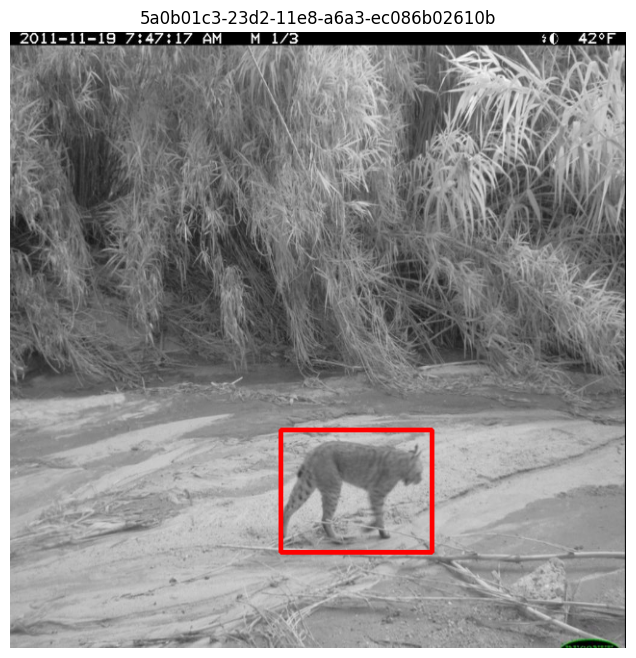

In [15]:
# Run the full combined pipeline on the same test example :--
final_test_image , final_test_image_bbox = image_pre_processing(test_image_path, test_image_id, test_image_annotation["bbox"])

print(f"Shape = {final_test_image.shape}")
print("Pixels range after image resizing")
print(f"{final_test_image.min():.2f} to {final_test_image.max():.2f}")
print("bbox before pre_proessing")
print(f"{test_image_annotation}")
print("After preprocessing")
print(f"{final_test_image_bbox}")

# Visualise it
display_test = (final_test_image * 255).astype("uint8")
display_test = cv2.cvtColor(display_test, cv2.COLOR_BGR2RGB)
x, y, w, h = final_test_image_bbox
cv2.rectangle(display_test, (int(x), int(y)), (int(x + w), int(y + h)), (255, 0, 0), 3)
plt.figure(figsize=(8, 8))
plt.imshow(display_test)
plt.axis("off")
plt.title(test_image_id)
plt.show()


In [20]:
# Total annotation count per category, across the FULL dataset (before filtering to available images)
print("Category counts (full dataset):")
for cat in final_categories:
    cat_id = cat["id"]
    cat_name = cat["name"]
    count = complete_category_count[cat_id]
    print(f"  {cat_name} (id {cat_id}): {count}")

print("\n" + "="*50 + "\n")

# Actual counts restricted to images that exist LOCALLY (what you actually trained on)
print("Category counts (local downloaded images only):")
local_category_count = Counter()

for annotation in data_bbox["annotations"]:
    if annotation["category_id"] in final_categories_id:
        if (annotation["image_id"] + ".jpg") in images_downloaded:
            local_category_count[annotation["category_id"]] += 1

for cat in final_categories:
    cat_id = cat["id"]
    cat_name = cat["name"]
    count = local_category_count[cat_id]
    print(f"  {cat_name} (id {cat_id}): {count}")

Category counts (full dataset):
  bobcat (id 6): 5048
  opossum (id 1): 12134
  coyote (id 9): 6505
  raccoon (id 3): 7908
  bird (id 11): 4026
  dog (id 8): 2860
  cat (id 16): 4391
  squirrel (id 5): 2648
  rabbit (id 10): 6025
  skunk (id 7): 1198
  lizard (id 14): 177
  rodent (id 99): 1842
  deer (id 34): 6428
  fox (id 51): 1099


Category counts (local downloaded images only):
  bobcat (id 6): 4123
  opossum (id 1): 11741
  coyote (id 9): 4587
  raccoon (id 3): 6898
  bird (id 11): 1521
  dog (id 8): 2560
  cat (id 16): 4233
  squirrel (id 5): 2441
  rabbit (id 10): 4772
  skunk (id 7): 700
  lizard (id 14): 0
  rodent (id 99): 469
  deer (id 34): 179
  fox (id 51): 8


In [17]:
# We need to rewrite our valid catogories(Catogories which is suitable for model training) in this :--
complete_category_count = Counter()
for annotation in data_bbox["annotations"]:
    complete_category_count[annotation["category_id"]]=complete_category_count[annotation["category_id"]] + 1

print("Total categories")
print(f"{len(complete_category_count)}")


Total categories
20


In [18]:
# We need to write now filtered categories which we did earlier in our data_eploration notebook
final_categories = []
final_categories_id = []
for category in data_bbox["categories"]:
    num = complete_category_count[category["id"]]
    if num > 100 and category["name"]!= "empty" and category["name"]!= "car":
        final_categories.append(category)
        final_categories_id.append(category["id"])

print("Categories after filter")
print(f"{len(final_categories)}")
print("id as well")
print(f"{len(final_categories_id)}")


Categories after filter
14
id as well
14


In [19]:
# Now we need to run the pipeline across full dataset and we need to save that as well on our memory:--
# So we need to convert annotations from list into an tidy group:--
annotation_image = defaultdict(list)

for annotation in data_bbox["annotations"]:
    if annotation["category_id"] in final_categories_id:
        annotation_image[annotation["image_id"]].append(annotation)

print("Images with all valid annotation")
print(f"{len(annotation_image)}")


Images with all valid annotation
59142


Testing image: 59f2c4e8-23d2-11e8-a6a3-ec086b02610b
Category ID: 3


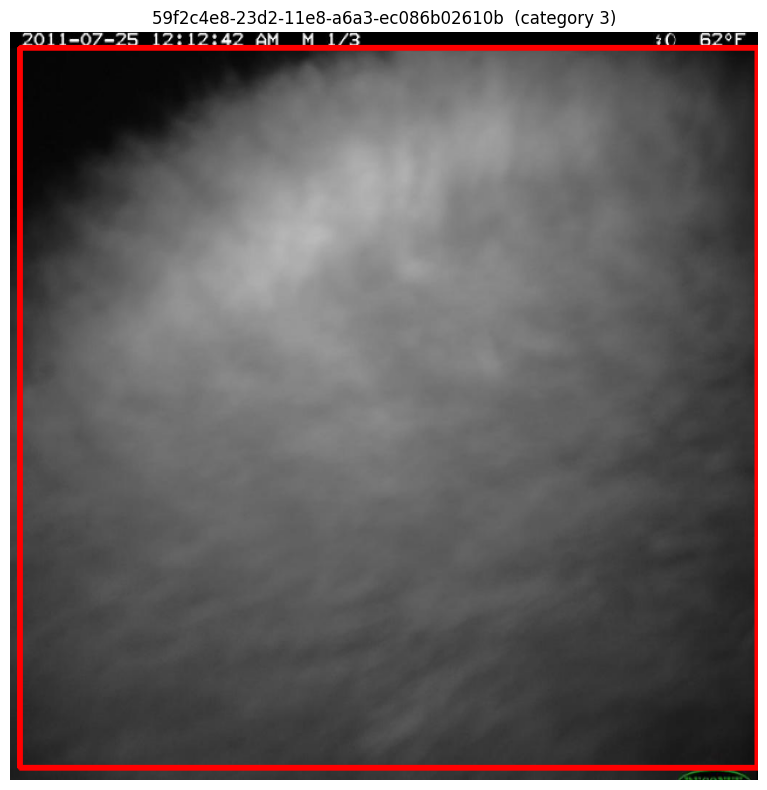

In [29]:
# ============================================================
# Random example across ALL categories — re-run this cell anytime
# to see a fresh random image from the dataset with its bbox drawn
# ============================================================
def find_good_example_any_category(min_area=3000, margin=2, seed=None):
    if seed is not None:
        random.seed(seed)

    category_id = random.choice(final_categories_id)

    candidates = []
    for ann in data_bbox["annotations"]:
        if ann["category_id"] != category_id:
            continue
        img_id = ann["image_id"]
        if (img_id + ".jpg") not in images_downloaded:
            continue
        if img_id not in image_dimensions:
            continue
        img_w, img_h = image_dimensions[img_id]
        x, y, w, h = ann["bbox"]
        if x < margin or y < margin:
            continue
        if (x + w) > (img_w - margin) or (y + h) > (img_h - margin):
            continue
        area = w * h
        if area < min_area:
            continue
        candidates.append((area, img_id, ann))

    if not candidates:
        return find_good_example_any_category(min_area=min_area, margin=margin, seed=None)

    candidates.sort(reverse=True, key=lambda c: c[0])
    top_candidates = candidates[:20]
    chosen = random.choice(top_candidates)
    return chosen[1], chosen[2]


random_image_id, random_annotation = find_good_example_any_category(seed=None)

print(f"Testing image: {random_image_id}")
print(f"Category ID: {random_annotation['category_id']}")

random_image_path = os.path.join(folder_image_path, random_image_id + ".jpg")
resized_img, sx, sy = image_resizing(random_image_path, random_image_id)
resized_img_rgb = cv2.cvtColor(resized_img, cv2.COLOR_BGR2RGB)
rx, ry, rw, rh = bbox_resizing(random_annotation["bbox"], sx, sy)
cv2.rectangle(resized_img_rgb, (int(rx), int(ry)), (int(rx + rw), int(ry + rh)), (255, 0, 0), 3)

plt.figure(figsize=(8, 8))
plt.imshow(resized_img_rgb)
plt.axis("off")
plt.title(f"{random_image_id}  (category {random_annotation['category_id']})")
plt.tight_layout()
plt.show()


In [17]:
# Now we are going to build full pre-processing loop which goes through whole data_set
prepared_images_folder = "D:\\Camera_trap\\data\\processed_data"
os.makedirs(prepared_images_folder , exist_ok =True)
print("The processed folder is ready to use")
print(f"{prepared_images_folder}")


The processed folder is ready to use
D:\Camera_trap\data\processed_data


In [ ]:
# Pre-processing loop:--
# Note: the corrected image_pre_processing() below now uses the ORIGINAL
# image dimensions (from the annotation file) to compute scale factors,
# not the downloaded 'small' file's actual dimensions. This only affects
# the bbox coordinates saved into prepared_annotations.json (used for
# visualisation) — the saved RGB image itself is unaffected, since your
# model training pipeline (Camera_Dataset etc.) never reads the bbox
# values at all, only the resized image and its species label.
prepared_annotations = []
num = 0
skipped_missing = 0

for image_id, annotations in annotation_image.items():
    image_path = os.path.join(folder_image_path, image_id + ".jpg")
    # If image doesn't exist then it will skip automatically :--
    if not os.path.exists(image_path):
        skipped_missing += 1
        continue

    prepared_images, _ = image_pre_processing(image_path, image_id, annotations[0]["bbox"])

    prepared_images_path = os.path.join(prepared_images_folder, image_id + ".jpg")
    cv2.imwrite(prepared_images_path, (prepared_images * 255).astype("uint8"))

    for annotation in annotations:
        _, prepared_bbox = image_pre_processing(image_path, image_id, annotation["bbox"])
        prepared_annotations.append({"image_id": image_id,"category_id": annotation["category_id"],"bbox": prepared_bbox})

    num = num + 1
    if num % 1000 == 0:
        print(f"Total prepared images: {num}")

print(f"Done! Total processed: {num}")
print(f"Skipped (image file missing): {skipped_missing}")


Total prepared images: 1000


In [ ]:
# We have saved full pre-processed dataset on the disk:--
# Saving annotation of pre-processed to a different json file
annotation_processed_path = "D:\\Camera_trap\\data\\processed_data\\prepared_annotations.json"

with open (annotation_processed_path, "w") as f:
    json.dump(prepared_annotations , f)

print("Number of annotation")
print(f"{len(prepared_annotations)}")


In [ ]:
# Phase-4 Pre-processing completed
# Note for report/viva: the RGB images saved to processed_data/ are
# unaffected by the bbox coordinate fix, since bounding boxes were
# never used to crop training images — only for visualisation. Model
# training results (ResNet50, Fusion, Siamese) are not impacted by
# this correction.
